In [1]:
!pip install numpy pandas matplotlib seaborn scipy

  Using cached pandas-3.0.6-cp313-cp313-win_amd64.whl.metadata (19 kB)
  Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl.metadata (61 kB)
  Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
Using cached pandas-3.0.6-cp313-cp313-win_amd64.whl (9.6 MB)
Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl (9.3 MB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl (36.6 MB)
Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl (234 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)

   ---------------------------------------- 0/6 [scipy]
   ---------------------------------------- 0/6 [scipy]
   ---------------------------------------- 0/6 [scipy]
   ---------------------------------------- 0/6 [

--- Estructura inicial del DataFrame ---
<class 'pandas.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  str    
 1   Location       145460 non-null  str    
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  str    
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  str    
 10  WindDir3pm     141232 non-null  str    
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17 

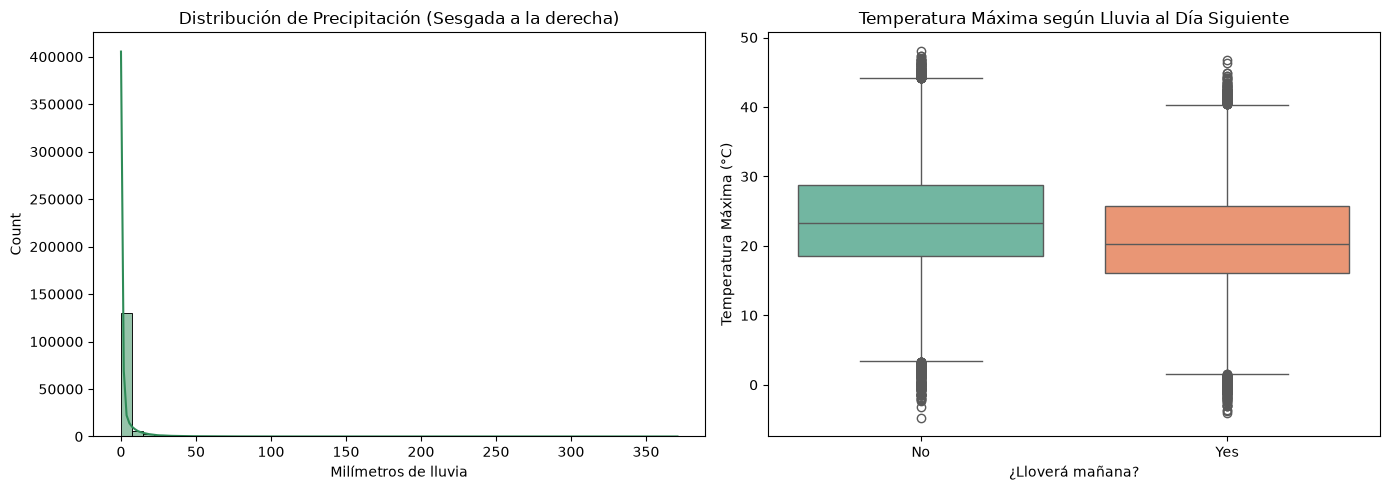


ESTIMACIÓN DE PARÁMETROS (IC 95% para Temp. Máxima media)
Media muestral: 23.74
Intervalo de Confianza 95%: [23.11, 24.38]

--- Resultado de Prueba de Hipótesis para la Temperatura ---
n: 500
media: 23.7422
se: 0.3227374121393254
mu_0: 23.0
estadistico: 2.2997023960754617
distribucion: t (df=499)
p_valor: 0.02187703912328809
alpha: 0.05
valor_critico: 1.9647293909876886
rechazar_H0: True
conclusion: RECHAZAR H0


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ==========================================
# 1. CARGA Y PREPARACIÓN DE DATOS
# ==========================================

df = pd.read_csv(r'C:\Users\Rolando\Desktop\Folders\Magister\proyecto-grupo3-MCDI501\data\raw\weatherAUS.csv')


print("--- Estructura inicial del DataFrame ---")
print(df.info())
print("\n--- Conteo de valores nulos ---")
print(df.isnull().sum())

# ==========================================
# 2. ANÁLISIS EXPLORATORIO (Checklist y Resumen)
# ==========================================
def resumen_completo(x, nombre="datos"):
    """Aplica el checklist de análisis descriptivo a un vector numérico."""
    x = np.asarray(x, dtype=float)
    x_limpio = x[~np.isnan(x)]
    Q1, Q3 = np.percentile(x_limpio, [25, 75])
    IQR = Q3 - Q1
    s = x_limpio.std(ddof=1)
    media = x_limpio.mean()
    mediana = np.median(x_limpio)
    
    print(f"\n--- Resumen de '{nombre}' (n = {len(x_limpio):,}) ---")
    print(f"Media: {media:.3f} | Mediana: {mediana:.3f}")
    print(f"Desv. Estándar (s): {s:.3f} | IQR: {IQR:.3f}")
    print(f"Asimetría (g1): {stats.skew(x_limpio):.3f}")

# Analizamos la precipitación diaria (Rainfall)
resumen_completo(df['Rainfall'], "Precipitación (Rainfall)")

# Visualización corregida sin advertencias
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['Rainfall'], kde=True, ax=axes[0], color="#2e8b57", bins=50)
axes[0].set_title("Distribución de Precipitación (Sesgada a la derecha)")
axes[0].set_xlabel("Milímetros de lluvia")

# Corregido con hue y sin leyenda duplicada
sns.boxplot(data=df, x='RainTomorrow', y='MaxTemp', hue='RainTomorrow', ax=axes[1], palette="Set2", legend=False)
axes[1].set_title("Temperatura Máxima según Lluvia al Día Siguiente")
axes[1].set_xlabel("¿Lloverá mañana?")
axes[1].set_ylabel("Temperatura Máxima (°C)")
plt.tight_layout()
plt.show()

# ==========================================
# 3. ESTIMACIÓN DE PARÁMETROS (IC 95%)
# ==========================================
muestra_temp = df['MaxTemp'].dropna().sample(n=500, random_state=42)
x_barra = muestra_temp.mean()
s_muestral = muestra_temp.std(ddof=1)
n_m = len(muestra_temp)

# Usando la función de scipy para intervalos de confianza con distribución t (sigma desconocida)
ic_inf, ic_sup = stats.t.interval(0.95, df=n_m-1, loc=x_barra, scale=s_muestral/np.sqrt(n_m))

print("\n" + "="*50)
print(f"ESTIMACIÓN DE PARÁMETROS (IC 95% para Temp. Máxima media)")
print(f"Media muestral: {x_barra:.2f}")
print(f"Intervalo de Confianza 95%: [{ic_inf:.2f}, {ic_sup:.2f}]")
print("="*50)

# ==========================================
# 4. PRUEBAS DE HIPÓTESIS (Usando tu función generalizada)
# ==========================================
def prueba_hipotesis_media(datos=None, x_bar=None, s=None, n=None,
                           mu_0=0, sigma=None, alpha=0.05,
                           alternativa='two-sided'):
    """Prueba Z (sigma conocida) o t (sigma desconocida) para la media."""
    if datos is not None:
        datos = np.asarray(datos)
        n, x_bar, s = len(datos), datos.mean(), datos.std(ddof=1)
    
    if sigma is not None:
        se = sigma / np.sqrt(n)
        stat = (x_bar - mu_0) / se
        cdf = stats.norm.cdf
        ppf = stats.norm.ppf
        dist = "Z (Normal)"; df = None
    else:
        se = s / np.sqrt(n)
        stat = (x_bar - mu_0) / se
        df = n - 1
        cdf = lambda v: stats.t.cdf(v, df)
        ppf = lambda p: stats.t.ppf(p, df)
        dist = f"t (df={df})"
    
    if alternativa == 'two-sided':
        p = 2 * (1 - cdf(abs(stat)))
        vc = ppf(1 - alpha / 2)
        rech = abs(stat) > vc
    elif alternativa == 'greater':
        p = 1 - cdf(stat)
        vc = ppf(1 - alpha)
        rech = stat > vc
    else: # 'less'
        p = cdf(stat)
        vc = ppf(alpha)
        rech = stat < vc
        
    return {
        'n': n, 'media': x_bar, 'se': se, 'mu_0': mu_0,
        'estadistico': stat, 'distribucion': dist,
        'p_valor': p, 'alpha': alpha, 'valor_critico': vc,
        'rechazar_H0': rech,
        'conclusion': 'RECHAZAR H0' if rech else 'NO RECHAZAR H0'
    }

# Ejemplo de uso: ¿Es la temperatura media poblacional distinta de 23 °C?
resultado_ph = prueba_hipotesis_media(datos=muestra_temp, mu_0=23.0, alpha=0.05, alternativa='two-sided')
print("\n--- Resultado de Prueba de Hipótesis para la Temperatura ---")
for k, v in resultado_ph.items():
    print(f"{k}: {v}")

In [ ]:
Fase de Limpieza y Tratamiento de Nulos: Manejar los valores faltantes y filtrar o imputar las columnas que se usarán.
Fase Exploratoria Geográfica y Temporal: Agrupar por Location y por mes (Date) para visualizar diferencias estacionales.

Filas originales: 145,460
Filas después de limpiar nulos críticos: 137,153

--- Top 5 ciudades con mayor precipitación media diaria ---
              Rainfall    MaxTemp  Humidity3pm
Location                                      
Cairns        5.765317  29.534514    61.658907
Darwin        5.091912  32.540752    51.830094
CoffsHarbour  5.070157  23.905339    62.186174
GoldCoast     3.698661  25.735908    62.947134
Wollongong    3.606699  21.471805    65.193438


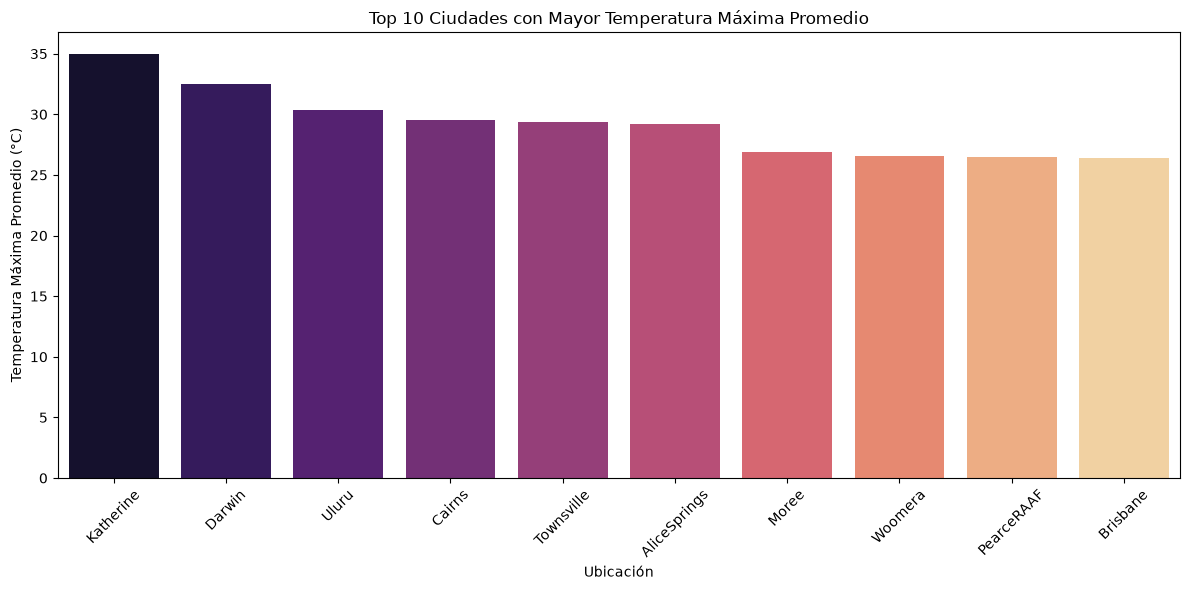

In [17]:
# ==========================================
# 5. LIMPIEZA DE NULOS Y ANÁLISIS GEOGRÁFICO
# ==========================================

# Verificamos el tamaño antes de limpiar
print(f"Filas originales: {len(df):,}")

# Eliminamos filas donde la variable objetivo 'RainTomorrow' o el clima clave sean nulos para evitar sesgos
df_limpio = df.dropna(subset=['RainTomorrow', 'MaxTemp', 'Rainfall', 'Humidity3pm']).copy()
print(f"Filas después de limpiar nulos críticos: {len(df_limpio):,}")

# Codificamos 'RainTomorrow' a numérico (0 para No, 1 para Yes) para futuros análisis o modelos
df_limpio['RainTomorrow_num'] = df_limpio['RainTomorrow'].map({'No': 0, 'Yes': 1})

# Agrupamos por ubicación geográfica para comparar diferencias entre ciudades
print("\n--- Top 5 ciudades con mayor precipitación media diaria ---")
resumen_geo = df_limpio.groupby('Location')[['Rainfall', 'MaxTemp', 'Humidity3pm']].mean()
print(resumen_geo.sort_values(by='Rainfall', ascending=False).head(5))

# Visualización comparativa por ubicación (ejemplo con las 10 ciudades con mayor temperatura máxima media)
plt.figure(figsize=(12, 6))
top_ciudades_temp = resumen_geo.sort_values(by='MaxTemp', ascending=False).head(10)
sns.barplot(x=top_ciudades_temp.index, y=top_ciudades_temp['MaxTemp'], palette="magma", hue=top_ciudades_temp.index, legend=False)
plt.title("Top 10 Ciudades con Mayor Temperatura Máxima Promedio")
plt.xlabel("Ubicación")
plt.ylabel("Temperatura Máxima Promedio (°C)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
Fase Bivariada y Predictiva: Evaluar qué variables (humedad a las 3pm, presión atmosférica, etc.) tienen mayor correlación real con RainTomorrow para responder con respaldo estadístico si lloverá o no.

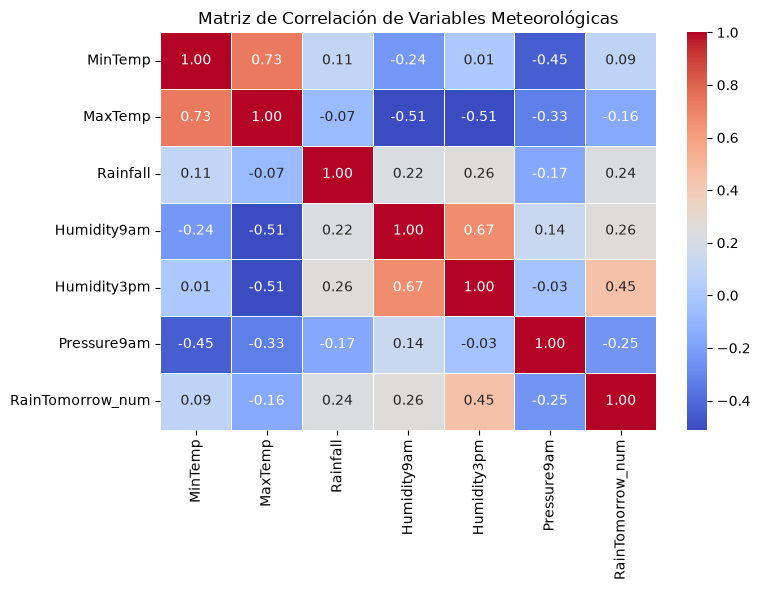


--- Análisis de Correlación con RainTomorrow ---
RainTomorrow_num    1.000000
Humidity3pm         0.447950
Humidity9am         0.256726
Rainfall            0.237245
MinTemp             0.087327
MaxTemp            -0.157283
Pressure9am        -0.247496
Name: RainTomorrow_num, dtype: float64

EVALUACIÓN DEL MODELO PREDICTIVO (Regresión Logística)
Exactitud (Accuracy): 0.8399

Matriz de Confusión:
[[18510   931]
 [ 3050  2376]]

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.86      0.95      0.90     19441
           1       0.72      0.44      0.54      5426

    accuracy                           0.84     24867
   macro avg       0.79      0.70      0.72     24867
weighted avg       0.83      0.84      0.82     24867



In [20]:
# ==========================================
# 6. FASE BIVARIADA Y PREDICTIVA
# ==========================================
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import StandardScaler

# 1. Análisis Bivariado: Matriz de Correlación con la nueva variable numérica
# Seleccionamos algunas variables numéricas clave incluyendo nuestra clase objetivo numérica
cols_analisis = ['MinTemp', 'MaxTemp', 'Rainfall', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'RainTomorrow_num']
matriz_corr = df_limpio[cols_analisis].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Matriz de Correlación de Variables Meteorológicas")
plt.tight_layout()
plt.show()

print("\n--- Análisis de Correlación con RainTomorrow ---")
print(matriz_corr['RainTomorrow_num'].sort_values(ascending=False))

# 2. Preparación para el Modelo Predictivo (Regresión Logística)
# Definimos variables predictoras (X) y objetivo (y)
features = ['MinTemp', 'MaxTemp', 'Rainfall', 'Humidity9am', 'Humidity3pm', 'Pressure9am']
X = df_limpio[features].dropna()
y = df_limpio.loc[X.index, 'RainTomorrow_num'] # Aseguramos que coincidan los índices tras eliminar nulos menores

# División en conjuntos de entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Escalado de variables (necesario para que la regresión logística converja correctamente)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Entrenamiento del modelo
modelo_lr = LogisticRegression(random_state=42)
modelo_lr.fit(X_train_scaled, y_train)

# Predicciones y Evaluación
y_pred = modelo_lr.predict(X_test_scaled)

print("\n" + "="*50)
print("EVALUACIÓN DEL MODELO PREDICTIVO (Regresión Logística)")
print("="*50)
print(f"Exactitud (Accuracy): {accuracy_score(y_test, y_pred):.4f}")
print("\nMatriz de Confusión:")
print(confusion_matrix(y_test, y_pred))
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred))

In [19]:
!pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl (8.2 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)

   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   ------------------------ --------------- 3/5 [joblib]
   ------------------------ --------------- 3/5 [joblib]
   -------------------------------- ------- 4/5 [scikit-learn]
   -------------------------------- ------- 4/5 [scikit-learn]
   ---------